# 03 Diagnose der Nutzer-Dips

Stand: 30.10.2026. Quelle: schreibgeschützte SQL-Abfragen auf der vollständigen TravelTide-Datenbank
(5.408.063 Sessions vom 01.04.2021 bis 28.07.2023). Die vorliegenden Kohorten-CSVs dienen
ausschließlich dem grafischen Indexvergleich. Es wurden keine Projektdateien verändert.

## 1. Datenbruch ab 21.07.2023 – stark belegt
Am 20.07. sind 16.615 Sessions erfasst, am 21.07. nur 366 (−97,8 %).
Ab 21.07. bis zum Ende am 28.07. haben sämtliche erfassten Sessions ein Buchungsflag.
Sessions ohne Buchung fehlen vollständig. Gleichzeitig liegen die Pageclicks nur noch zwischen
10 und 200 und je Tag entspricht die Sessionzahl genau der Nutzerzahl.

**Vermutung:** Unterschiedliche zeitliche Abdeckung von Sessionarten, eine unvollständige
Datenlieferung oder ein Wechsel der Erzeugungs-/Erfassungslogik. Ein echter allgemeiner
Nachfragerückgang allein erklärt diesen abrupten Wechsel der Datenzusammensetzung nicht gut.
Welche technische Ursache vorliegt, lässt sich ohne Herkunfts-/Importinformationen nicht klären.

Die Woche ab 17.07. ist bereits betroffen, obwohl sie sieben verschiedene Datentage enthält.
Die Woche ab 24.07. hat zusätzlich nur fünf Datentage. Sieben Datentage beweisen keine
vollständige Erfassung aller Sessionarten. Für einen unverzerrten Wochenvergleich bzw. eine
Trendfortschreibung zunächst nur volle Wochen bis einschließlich 10.–16.07.2023 verwenden.

## 2. April-Dip – Rückgang der Aktivität, nicht primär der Buchungsquote
Von 27.03. auf 03.04.2023 sinkt die wöchentliche Nutzerzahl von 105,559 auf 76,010
(-28.0 %). Beide Wochen enthalten sieben Datentage; sämtliche
24 Uhrzeiten sind im jeweiligen Wochenbestand vertreten. Ein kompletter fehlender Tag
oder ein vollständiges Ausfallen einer Tagesstunde erklärt diesen Dip nicht; partielle
Erfassungslücken bleiben damit aber nicht ausgeschlossen.

| Kennzahl, ungefilterte Daten | Woche 27.03. | Woche 03.04. |
|---|---:|---:|
| Aktive Nutzer | 105,559 | 76,010 |
| Buchende Nutzer | 49,206 | 35,307 |
| Nutzerbezogene Buchungsquote | 46.61 % | 46.45 % |
| Erstmals in der gesamten Sessionhistorie beobachtet | 19,499 | 19,478 |
| Nach mindestens einer Woche Pause wieder aktiv | 69,571 | 45,466 |
| Auch in der unmittelbaren Vorwoche aktiv | 16,489 | 11,066 |

Die erstmalig beobachteten Nutzer entsprechen in diesen Wochen den registrierten Neunutzern.
Ihre Zahl bleibt praktisch gleich. Vor allem die Reaktivierten fallen um
24,105; die unmittelbar Wiederkehrenden sinken um
5,423. Zusammen mit 21 weniger
erstmals beobachteten Nutzern ergibt dies exakt 29,549 weniger aktive Nutzer.
Die Wiederkehrrate aus der Vorwoche sinkt von
14.10 % auf
10.48 %. „Ausbleibend“ bedeutet nur in dieser Woche inaktiv, nicht endgültig abgewandert.

Die Flug-Angebotsquote steigt von 17,89 % auf 18,72 %, die Hotel-Angebotsquote von 14,26 %
auf 14,96 %. Die sessionbezogene Stornoquote steigt von 1,54 % auf 2,23 %; daraus folgt
kein Nachweis, dass Stornos den Aktivitätsrückgang verursachen. Eine plötzliche Verknappung
der Rabattangebote wird durch diese Anteile nicht gestützt. Preise wurden in dieser Diagnose
nicht untersucht.

**Vermutung:** Ein zeitlich begrenzter Rückgang der Nutzung durch bereits bekannte Nutzer
(z. B. saisonale Veränderung oder Änderung einer Reaktivierungsmaßnahme), kein primärer
Einbruch der Neuregistrierung oder der beobachteten Buchungsneigung aktiver Nutzer.
Auch 2022 fällt die Aktivität von Ende März auf Anfang April, und im Spätsommer gibt es
weitere wiederkehrende Brüche. Das macht einen periodischen Mechanismus plausibel;
mit nur wenigen Wiederholungen ist weder Saisonalität noch ein Kampagneneffekt bewiesen.
Ein synthetisches Erzeugungsmuster oder eine Änderung der Datenbereitstellung bleibt ebenfalls möglich.

## 3. Einordnung und nächste Prüfung
Die Hauptursache des letzten Dips ist vermutlich ein Datenabdeckungsproblem. Der April-Dip
ist ein davon getrenntes Aktivitätsmuster im ungefilterten Bestand. Der langfristige negative
Verlauf der gefilterten Kohorte darf nicht als allgemeiner Plattformtrend interpretiert werden.

Zur Klärung: Datenherkunft und Enddatum je Sessionart bestätigen lassen; für März/April
Kampagnen-/Versandpläne und Ereignisprotokolle vergleichen. Ohne diese Informationen bleibt
die geschäftliche Ursache eine Hypothese.

## Definitionen
UTC, Wochenbeginn Montag. Nutzer pro Woche einmal, Buchung = mindestens ein Flug-/Hotelflag.
Keine automatische Entfernung späterer Stornos. Die Bewegungsrechnung nutzt disjunkte
Gruppen: aktiv in der Vorwoche, erstmals überhaupt aktiv, oder nach Pause wieder aktiv.
Die erste Woche des Diagnosefensters wird nicht als Wiederkehrmessung interpretiert.
Aggregierte Wochenpreise, Einnahmen oder eine tatsächliche Kündigung werden nicht abgeleitet.


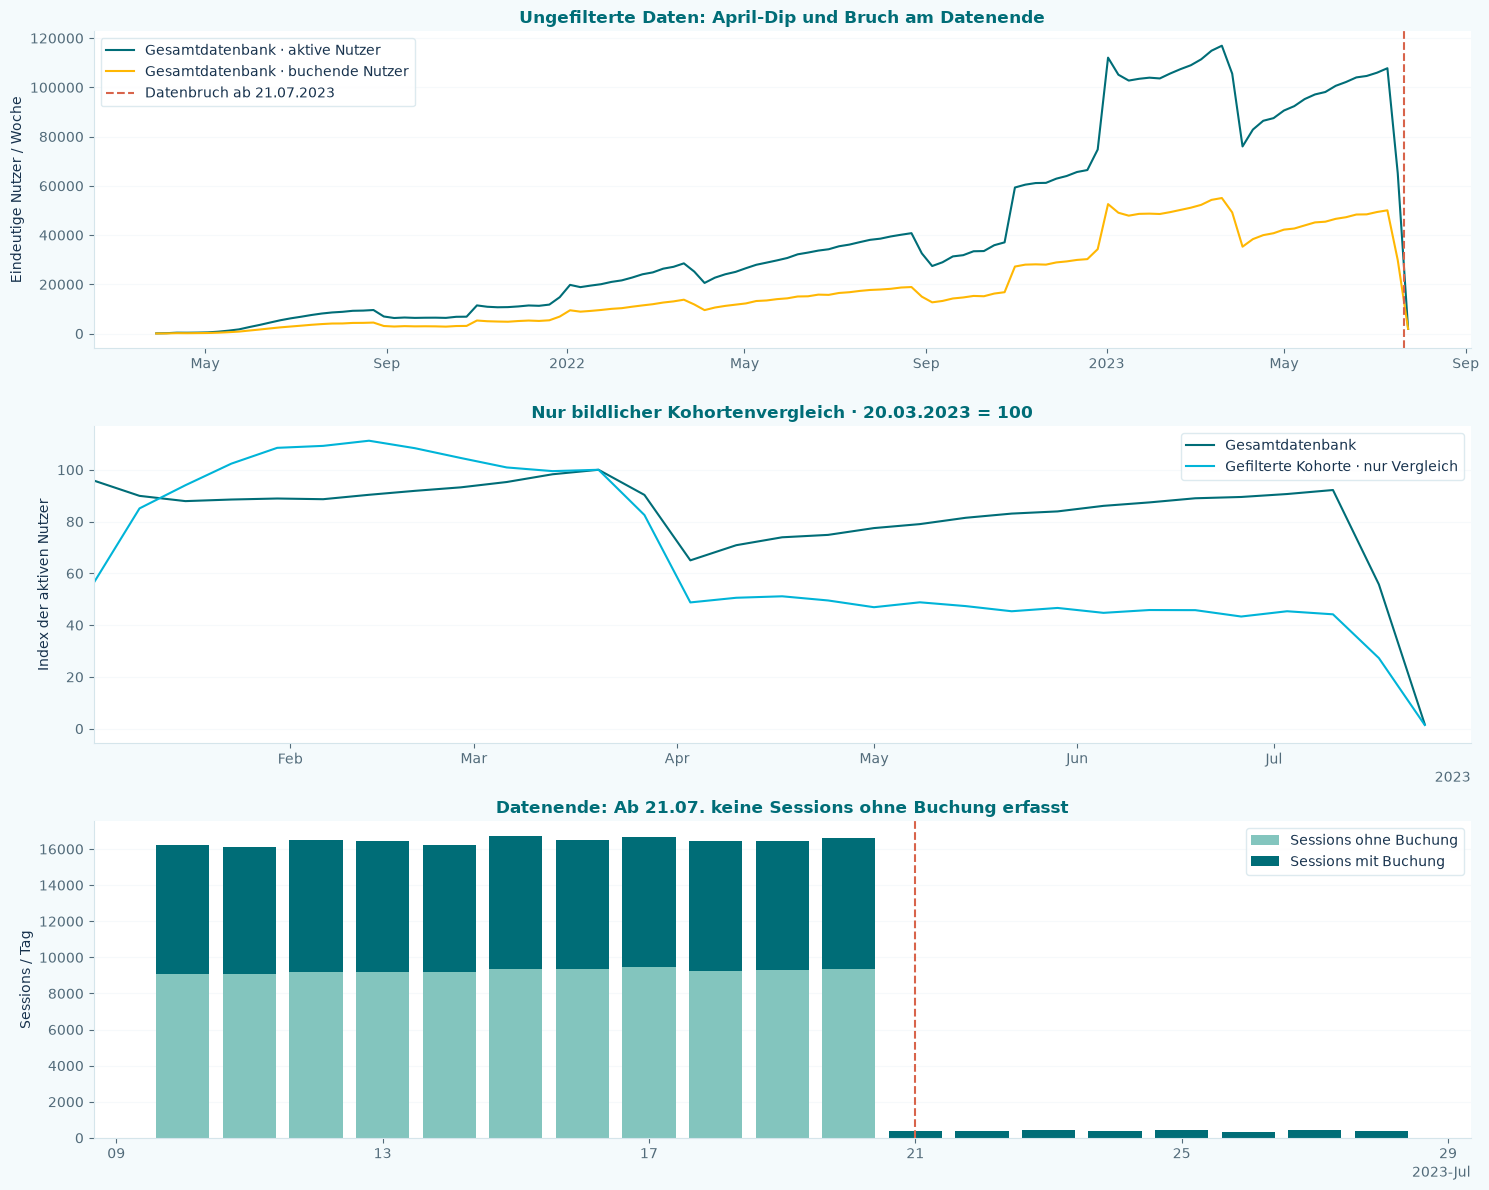

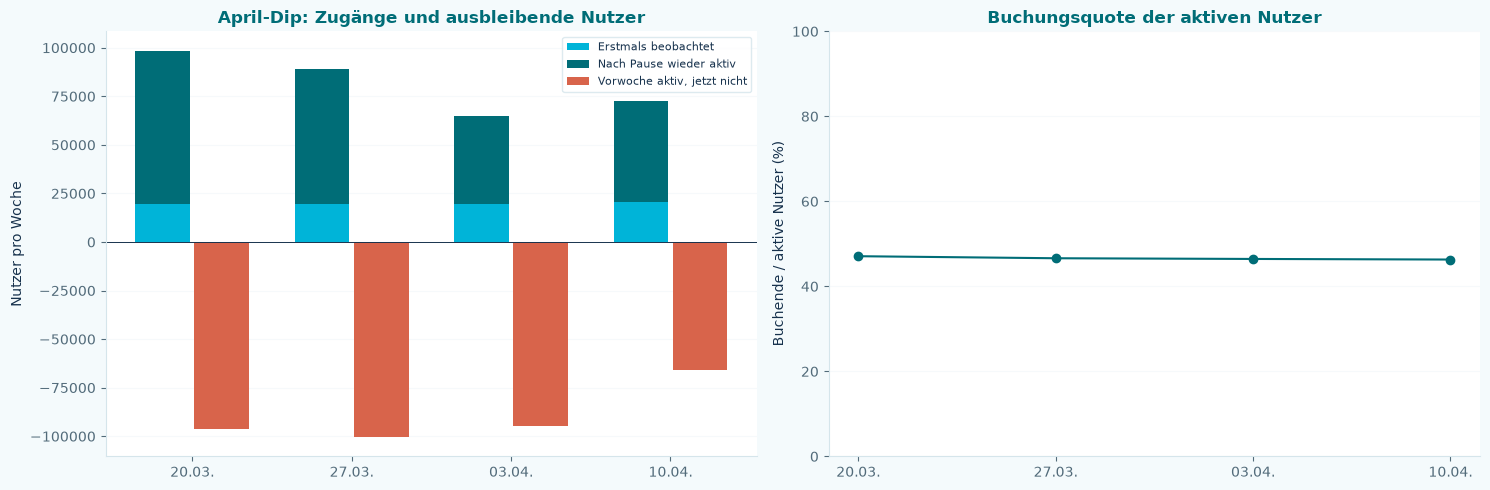

In [3]:
import config
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Mitgelieferte SQL-Aggregate; Kohorte ausschließlich als grafischer Vergleich.
# Absoluter Datenpfad relativ zum Projektordner aus config.py.
DATA = config.DATA_FOLDER / "dip_analysis"
required_files = [
    "all_weekly.csv", "cohort_weekly.csv", "daily_end_of_data.csv",
    "april_user_flows.csv", "april_context.csv",
]
missing_files = [name for name in required_files if not (DATA / name).is_file()]
if missing_files:
    raise FileNotFoundError(
        f"Diagnose-Dateien fehlen unter {DATA}: " + ", ".join(missing_files)
    )
whole = pd.read_csv(DATA / "all_weekly.csv", parse_dates=["week"])
cohort = pd.read_csv(DATA / "cohort_weekly.csv", parse_dates=["week"])
daily = pd.read_csv(DATA / "daily_end_of_data.csv", parse_dates=["day"])
flows = pd.read_csv(DATA / "april_user_flows.csv", parse_dates=["w"])
context = pd.read_csv(DATA / "april_context.csv", parse_dates=["week"])
THEME = config.THEME
PERK_COLORS = config.PERK_COLORS
# Diagrammgestaltung: einzige Farbquelle ist config.py.
def apply_config_plot_theme():
    plt.rcParams.update({
        "figure.facecolor": THEME["background"],
        "axes.facecolor": THEME["surface"],
        "savefig.facecolor": THEME["background"],
        "axes.titlecolor": THEME["primary"],
        "axes.titleweight": "bold",
        "axes.labelcolor": THEME["text"],
        "text.color": THEME["text"],
        "xtick.color": THEME["text_muted"],
        "ytick.color": THEME["text_muted"],
        "axes.edgecolor": THEME["border"],
        "grid.color": THEME["border"],
        "legend.facecolor": THEME["surface"],
        "legend.edgecolor": THEME["border"],
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.prop_cycle": plt.cycler(color=THEME["chart_colors"]),
    })
    # Negative / neutrale / positive Werte bleiben bei Korrelationen unterscheidbar.
    return plt.matplotlib.colors.LinearSegmentedColormap.from_list(
        "traveltide_diverging",
        [THEME["danger_border"], THEME["surface"], THEME["primary"]],
    )

def perk_plot_color(label):
    mapping = {
        "Kostenlose Stornierung": "Free Cancellation",
        "Kostenloses Gepäck": "Free Baggage",
        "Kostenlose Mahlzeiten": "Complimentary Meals",
        "Erste Hotelnacht kostenlos": "First Night Free",
        "Exklusive Rabatte": "Member Discounts",
    }
    return PERK_COLORS.get(mapping.get(str(label), str(label)), THEME["text_muted"])

THEME_DIVERGING_CMAP = apply_config_plot_theme()

fig,axes=plt.subplots(3,1,figsize=(15,12))
ax=axes[0]
ax.plot(whole.week,whole.users,color=THEME["primary"],label="Gesamtdatenbank · aktive Nutzer")
ax.plot(whole.week,whole.bookers,color=THEME["accent"],label="Gesamtdatenbank · buchende Nutzer")
ax.axvline(pd.Timestamp("2023-07-21"),color=THEME["danger_border"],linestyle="--",label="Datenbruch ab 21.07.2023")
ax.set(title="Ungefilterte Daten: April-Dip und Bruch am Datenende",ylabel="Eindeutige Nutzer / Woche")
ax.legend(loc="upper left")

# Gleicher Nullpunkt für die rein visuelle Gegenüberstellung, keine kausale Schätzung.
ax=axes[1]
base=pd.Timestamp("2023-03-20")
global_base=whole.set_index("week").loc[base,"users"]
cohort_base=cohort.set_index("week").loc[base,"users"]
ax.plot(whole.week,100*whole.users/global_base,color=THEME["primary"],label="Gesamtdatenbank")
ax.plot(cohort.week,100*cohort.users/cohort_base,color=THEME["secondary"],label="Gefilterte Kohorte · nur Vergleich")
ax.set_xlim(pd.Timestamp("2023-01-02"),pd.Timestamp("2023-07-31"))
ax.set(title="Nur bildlicher Kohortenvergleich · 20.03.2023 = 100",ylabel="Index der aktiven Nutzer")
ax.legend()

ax=axes[2]
ax.bar(daily.day,daily.no_booking,color=THEME["chart_colors"][2],label="Sessions ohne Buchung")
ax.bar(daily.day,daily.booked_sessions,bottom=daily.no_booking,color=THEME["primary"],label="Sessions mit Buchung")
ax.axvline(pd.Timestamp("2023-07-21"),color=THEME["danger_border"],linestyle="--")
ax.set(title="Datenende: Ab 21.07. keine Sessions ohne Buchung erfasst",ylabel="Sessions / Tag")
ax.legend()
for ax in axes:
    locator=mdates.AutoDateLocator(minticks=5,maxticks=10)
    ax.xaxis.set_major_locator(locator);ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.grid(axis="y",alpha=.2);ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

# April-Analyse: ausschließlich ungefilterte Daten; erste Fensterwoche nicht interpretieren.
april=flows.loc[flows.w.ge("2023-03-20")].copy()
april["booking_rate_pct"]=100*april.bookers/april.users
april["incoming"]=april.first_observed+april.reactivated
assert np.array_equal(april.users.to_numpy(),(april.returned+april.first_observed+april.reactivated).to_numpy())
assert np.allclose(april.users.diff().iloc[1:],(april.incoming-april.lost).iloc[1:])
fig,axes=plt.subplots(1,2,figsize=(15,5))
ax=axes[0]
ax.bar(april.w-pd.Timedelta(days=1.3),april.first_observed,width=2.4,color=THEME["secondary"],label="Erstmals beobachtet")
ax.bar(april.w-pd.Timedelta(days=1.3),april.reactivated,bottom=april.first_observed,width=2.4,color=THEME["primary"],label="Nach Pause wieder aktiv")
ax.bar(april.w+pd.Timedelta(days=1.3),-april.lost,width=2.4,color=THEME["danger_border"],label="Vorwoche aktiv, jetzt nicht")
ax.axhline(0,color=THEME["text"],linewidth=.7)
ax.set(title="April-Dip: Zugänge und ausbleibende Nutzer",ylabel="Nutzer pro Woche");ax.legend(fontsize=8)
ax=axes[1]
ax.plot(april.w,april.booking_rate_pct,marker="o",color=THEME["primary"])
ax.set_ylim(0,100);ax.set(title="Buchungsquote der aktiven Nutzer",ylabel="Buchende / aktive Nutzer (%)")
for ax in axes:
    ax.set_xticks(april.w);ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m."));ax.grid(axis="y",alpha=.2);ax.set_axisbelow(True)
fig.tight_layout();plt.show()
